# Sección 2 · Diversidad genética

*Ho, He, Fis, incertidumbre y gradiente latitudinal en* Nothofagus pumilio *(lenga)*

**Qué vamos a hacer:** (1) entender qué miden Ho, He y Fis, (2) calcularlos por sitio, (3) ponerles una barra de error, (4) preguntar si la diversidad cambia con la latitud, y (5) ver dos sesgos que pueden cambiar la respuesta.

> **Antes de empezar, anota tu predicción:** ¿esperas más diversidad al norte o al sur de la distribución de la lenga? ¿Por qué? La contrastaremos al final.

**Revisión de la tarea de la Sección 1:** comparte tus 5 líneas de Métodos (umbrales y justificación). ¿Cuál te costó más justificar? Hoy veremos cuánto pesa el **umbral de MAF** sobre la diversidad estimada.

## Objetivos de aprendizaje

1. Calcular **heterocigosidad observada (Ho)**, **esperada (He)** y **coeficiente de endogamia (Fis)** por sitio.
2. Cuantificar la **incertidumbre** de esas estimaciones con bootstrap sobre SNP, e interpretar el intervalo.
3. Poner a prueba una hipótesis biogeográfica: **¿cambia la diversidad con la latitud?**, reportando tamaño del efecto además del valor *p*.
4. Reconocer cómo el **filtro de MAF** y el **tamaño de muestra** pueden cambiar la respuesta.

In [1]:
# ---- Preparación (ejecutar primero) ----
options(repr.plot.width = 7, repr.plot.height = 4.5, repr.plot.res = 110)

source("R/helpers.R")
d <- load_clean(); G <- d$G; meta <- d$meta
meta$lat_sur <- abs(meta$lat)      # grados de latitud sur: mayor valor = más al sur

## 1. Los tres conceptos: Ho, He y Fis

Cada individuo diploide tiene en un SNP **0, 1 o 2 copias** del alelo alternativo. A partir de esos genotipos se definen tres cantidades:

- **Ho (heterocigosidad observada):** la proporción de individuos que son heterocigotos (genotipo 1). Se *cuenta*, no se modela.
- **He (heterocigosidad esperada):** imagina sacar al azar dos copias del gen de la población. He es la probabilidad de que sean **distintas**. Si el alelo alternativo tiene frecuencia *p*, y el otro *q = 1 − p*, entonces **He = 2pq**. Vale 0 si todos tienen el mismo alelo y llega a su máximo (0,5) cuando *p* = 0,5. Mide cuánta **variación** hay en la población, sin importar cómo se aparean los individuos.
- **Fis = 1 − Ho/He:** compara lo observado con lo esperado. Si los individuos se aparean al azar, Ho ≈ He y Fis ≈ 0.

**Cómo leer Fis**

- **Fis > 0 (déficit de heterocigotos):** endogamia, o que mezclaste grupos distintos sin saberlo (efecto Wahlund); también puede ser un artefacto técnico (el heterocigoto se llama mal y se lee como homocigoto).
- **Fis < 0 (exceso de heterocigotos):** apareamiento forzosamente cruzado (como en especies alógamas), pocos progenitores en la generación anterior, o un artefacto técnico (SNP parálogos). En lenga, Sekely et al. reportan Ho > He, es decir, Fis negativo.

Un ejemplo mínimo, un solo SNP en 10 individuos:

In [2]:
g  <- c(0, 0, 0, 1, 1, 1, 1, 2, 2, 0)   # genotipos de 10 individuos (copias del alelo ALT)
n  <- length(g)

p  <- mean(g) / 2          # frecuencia del alelo ALT: 8 copias de 20 = 0.4
ho <- mean(g == 1)         # 4 de 10 son heterocigotos = 0.4
he <- 2 * p * (1 - p)      # 2 x 0.4 x 0.6 = 0.48

c(p = p, Ho = ho, He = he, Fis = 1 - ho / he)   # Fis ~ 0.17: leve déficit de heterocigotos

p        Ho        He       Fis 
0.4000000 0.4000000 0.4800000 0.1666667

**Tres precisiones que usaremos en todo el análisis**

1. **De un SNP a un sitio.** Se promedian Ho y He sobre todos los SNP, y Fis se calcula con esos promedios (`1 − mean(Ho)/mean(He)`). Así los SNP casi monomórficos, que tienen He cercano a 0, no hacen inestable el cociente.
2. **Corrección por tamaño de muestra.** Con *n* individuos miras solo 2*n* copias. Con pocas copias se pierden alelos raros y 2pq sale algo bajo. La corrección de Nei multiplica por **2n/(2n − 1)**; en el ejemplo, 0,48 × 20/19 ≈ 0,505. Con muestras grandes casi no importa.
3. **Qué NO mide este He.** Solo entran posiciones **variables** que pasaron tus filtros. Por eso un He de ~0,3 no es "la diversidad del genoma" (donde casi todas las posiciones son idénticas). Sirve para **comparar sitios entre sí** con el mismo conjunto de SNP y el mismo filtro, no para compararlo con otros estudios. La diversidad nucleotídica (π) necesita incluir los sitios invariantes.

## 2. Diversidad por sitio

`diversity_by_pop()` devuelve, por sitio: número de individuos (`n_ind`), `Ho`, `He` (corregida), `Fis` y `prop_polim` (proporción de SNP que varían dentro del sitio; es menor que 1 porque con pocos individuos algunos SNP aparecen fijos por azar).

**¿Qué esperas?** Antes de ejecutar: ¿qué rango de He (0 a 0,5)? ¿Fis positivo o negativo?

In [3]:
div <- diversity_by_pop(G, meta$pop)
div <- merge(div, aggregate(lat_sur ~ pop, data = meta, FUN = mean), by = "pop")
div <- div[order(div$lat_sur), ]                    # de norte a sur

tabla <- div
tabla[sapply(tabla, is.numeric)] <- round(tabla[sapply(tabla, is.numeric)], 3)
tabla

,pop,n_ind,Ho,He,Fis,prop_polim,lat_sur
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,L01,12,0.324,0.337,0.037,0.928,35.870
2,L02,10,0.324,0.332,0.027,0.906,37.244
3,L03,12,0.323,0.331,0.027,0.915,37.913
4,L04,12,0.320,0.328,0.023,0.920,38.942
5,L05,12,0.316,0.323,0.022,0.914,40.061
6,L06,12,0.318,0.326,0.024,0.906,41.497
7,L07,12,0.316,0.325,0.028,0.903,42.026
8,L08,12,0.328,0.334,0.017,0.905,43.071
9,L09,11,0.318,0.329,0.032,0.890,43.761


## 3. Incertidumbre: bootstrap sobre SNP

Una cifra sin barra de error no es un resultado. Para ponerle una, usamos un **bootstrap**: remuestreamos los SNP *con reemplazo* (algunos se repiten, otros quedan fuera), recalculamos He y Fis, y repetimos 1.000 veces. El rango central de esas 1.000 réplicas (percentiles 2,5 % y 97,5 %) es un intervalo de confianza aproximado.

**Qué dice y qué no dice ese intervalo**

- Dice cuánto cambiaría He si hubieras muestreado **otros SNP** del genoma.
- **No** incluye la incertidumbre por haber muestreado solo ~12 árboles por sitio, que suele ser mayor (lo verás en la sección 5).
- Supone SNP **independientes**; por eso en el control de calidad se poda por ligamiento.

In [4]:
# He y Ho de cada SNP dentro de un sitio (misma fórmula que diversity_by_pop)
het_por_snp <- function(Gk) {
  n  <- colSums(!is.na(Gk)); p <- colMeans(Gk, na.rm = TRUE) / 2
  ok <- n > 1
  data.frame(he = ((2 * n / (2 * n - 1)) * 2 * p * (1 - p))[ok],
             ho = colMeans(Gk == 1, na.rm = TRUE)[ok])
}

boot_sitio <- function(Gk, B = 1000) {
  x  <- het_por_snp(Gk)
  ix <- replicate(B, sample(nrow(x), replace = TRUE), simplify = FALSE)
  he  <- sapply(ix, function(i) mean(x$he[i]))
  fis <- sapply(ix, function(i) 1 - mean(x$ho[i]) / mean(x$he[i]))
  c(He_lo = unname(quantile(he, .025)), He_hi = unname(quantile(he, .975)),
    Fis_lo = unname(quantile(fis, .025)), Fis_hi = unname(quantile(fis, .975)))
}

set.seed(1)
ic  <- t(sapply(div$pop, function(s) boot_sitio(G[meta$pop == s, ])))
div <- cbind(div, ic)
head(transform(div[, c("pop", "He", "He_lo", "He_hi")],
               He = round(He, 3), He_lo = round(He_lo, 3), He_hi = round(He_hi, 3)), 5)

,pop,He,He_lo,He_hi
,<chr>,<dbl>,<dbl>,<dbl>
1,L01,0.337,0.328,0.346
2,L02,0.332,0.322,0.342
3,L03,0.331,0.321,0.341
4,L04,0.328,0.319,0.337
5,L05,0.323,0.313,0.333


## 4. ¿Cambia la diversidad con la latitud?

Graficamos He de cada sitio con su intervalo, contra la **latitud sur en valor absoluto** (así una pendiente negativa significa "menos diversidad hacia el sur"). Ajustamos una recta y miramos su **tamaño**, no solo su p-valor.

> **Ojo con la interpretación.** Son 20 sitios, y los vecinos **no son independientes** (comparten historia). Un p-valor pequeño es evidencia *sugerente*, no definitiva. Fíjate además en que el eje y no parte de cero: las diferencias son pequeñas.

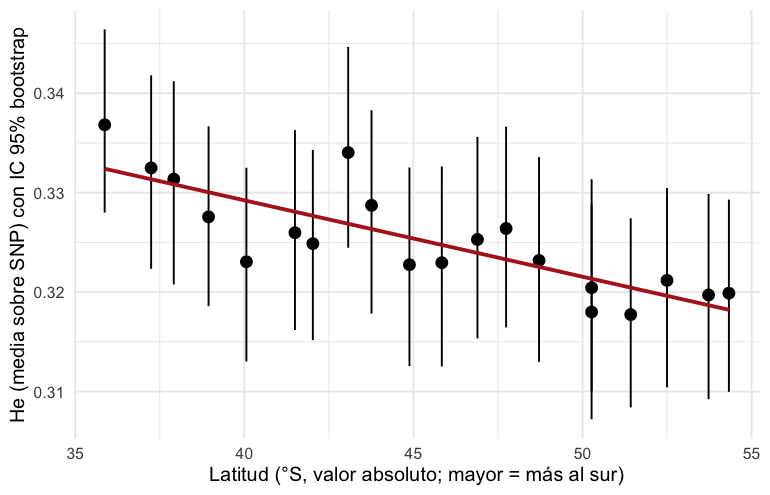

In [5]:
ggplot(div, aes(lat_sur, He)) +
  geom_pointrange(aes(ymin = He_lo, ymax = He_hi)) +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE, colour = "firebrick") +
  labs(x = "Latitud (°S, valor absoluto; mayor = más al sur)",
       y = "He (media sobre SNP) con IC 95% bootstrap")

In [6]:
m <- lm(He ~ lat_sur, data = div)
coef(summary(m))
confint(m)["lat_sur", ]
cor.test(div$lat_sur, div$He, method = "spearman")

# tamaño del efecto: cuánto cambia He de punta a punta del rango
cambio <- unname(coef(m)["lat_sur"]) * diff(range(div$lat_sur))
c(cambio_He = cambio, porcentaje_de_He_media = 100 * cambio / mean(div$He))

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),0.3599744298,0.0058365956,61.675410,2.119244e-22
lat_sur,-0.0007684415,0.0001277455,-6.015408,1.092007e-05


2.5 %        97.5 % 
-0.0010368250 -0.0005000581


	Spearman's rank correlation rho

data:  div$lat_sur and div$He
S = 2422, p-value = 5.696e-06
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
-0.8210526 


cambio_He porcentaje_de_He_media 
           -0.01418389            -4.36257249

**Cómo reportarlo:** la pendiente (con su intervalo), el cambio total de He en el rango y el porcentaje que representa. Un valor *p* muy pequeño con un cambio de pocos puntos porcentuales dice que el patrón es consistente, no que sea grande.

## 5. Dos sesgos que pueden cambiar la respuesta

### 5.1 El filtro de MAF (sesgo de verificación)

Al exigir una MAF mínima se eliminan los alelos raros, y los alelos raros son los que menos aportan a He. Subir el umbral **sube He** artificialmente. Revisa primero si tus datos ya vienen filtrados: si el mínimo de MAF es 0,05 o más, ya aplicaste un umbral.

In [7]:
maf_snp <- function(G) { p <- colMeans(G, na.rm = TRUE) / 2; pmin(p, 1 - p) }
m_all <- maf_snp(G)
min(m_all)                      # si es >= 0.05, tus datos ya vienen filtrados por MAF

res_maf <- do.call(rbind, lapply(c(0.05, 0.10, 0.20), function(u) {
  du <- diversity_by_pop(G[, m_all >= u, drop = FALSE], meta$pop)
  du <- merge(du, aggregate(lat_sur ~ pop, data = meta, FUN = mean), by = "pop")
  data.frame(maf_min = u, n_snp = sum(m_all >= u), He_media = mean(du$He),
             pendiente = unname(coef(lm(He ~ lat_sur, data = du))["lat_sur"]))
}))
round(res_maf, 4)

[1] 0.05021834

maf_min,n_snp,He_media,pendiente
<dbl>,<dbl>,<dbl>,<dbl>
0.05,1174,0.3251,-0.0008
0.10,1017,0.3561,-0.0008
0.20,726,0.4048,-0.0012


**Idea clave:** compara sitios solo con el mismo filtro, y declara el umbral en los Métodos. Si el umbral cambia mucho la pendiente, tu conclusión depende de una decisión arbitraria.

### 5.2 El tamaño de muestra

Submuestreamos 4, 6, 8 y 10 individuos por sitio (20 réplicas cada uno) y miramos cuánto varían He y Fis.

In [8]:
set.seed(2)
por_sitio <- split(seq_len(nrow(G)), meta$pop)

submuestra <- function(n) {
  idx <- unlist(lapply(por_sitio, function(i) sample(i, min(n, length(i)))))
  s <- diversity_by_pop(G[idx, ], meta$pop[idx])
  data.frame(n = n, He = s$He, Fis = s$Fis)
}
res_n <- do.call(rbind, lapply(c(4, 6, 8, 10), function(n)
  do.call(rbind, replicate(20, submuestra(n), simplify = FALSE))))

aggregate(cbind(He, Fis) ~ n, data = res_n,
          FUN = function(x) round(c(media = mean(x), sd = sd(x)), 4))

n,He,Fis
<dbl>,"<dbl[,2]>","<dbl[,2]>"
4,"0.3242, 0.0068","0.0242, 0.0164"
6,"0.3249, 0.0061","0.0270, 0.0138"
8,"0.3249, 0.0055","0.0268, 0.0110"
10,"0.3252, 0.0054","0.0274, 0.0093"


**Cómo leerlo:** la **media** de He casi no cambia (gracias a la corrección), pero la **dispersión** crece cuando hay pocos individuos, y mucho más para Fis. Con 4 o 6 individuos por sitio, una diferencia pequeña entre dos sitios puede ser puro azar.

---

## Ejercicios

**E1. ¿Qué estadístico muestra el gradiente?** Repite la regresión y el gráfico con `Ho` y con `Fis`. ¿Cambian las conclusiones?
> **Idea clave:** un estadístico puede mostrar gradiente y otro no; reporta los tres.

In [9]:
# for (v in c("He", "Ho", "Fis")) {
#   m <- lm(reformulate("lat_sur", response = v), data = div)
#   # imprime la pendiente y su intervalo de confianza; grafica v contra lat_sur
# }

**E2. ¿Depende el gradiente del filtro?** Con la tabla `res_maf`, ¿cambia el signo o el tamaño de la pendiente según el umbral de MAF? Escribe dos frases sobre qué umbral reportarías y por qué.

**E3 (reto). Bootstrap sobre individuos.** Para un solo sitio, remuestrea **individuos** (filas de `G`) en lugar de SNP y calcula el intervalo de He. ¿Es más ancho o más angosto que el de la sección 3? ¿Qué te dice sobre qué fuente de incertidumbre pesa más?

In [10]:
# idx <- replicate(1000, sample(nrow(Gk), replace = TRUE), simplify = FALSE)
# ... recalcula He con diversity_by_pop(Gk[i, ], rep("x", length(i)))$He

## Errores y dudas frecuentes

- **«Mi bootstrap da intervalos muy anchos»** → es lo esperable con pocos SNP o individuos; no es un error.
- **«Fis me da negativo en un sitio»** → posible con *n* pequeño o en especies alógamas; no interpretes un valor aislado.
- **«¿Puedo comparar mi He con el de un artículo?»** → solo si usan el mismo tipo de marcador y los mismos filtros (MAF, datos faltantes).

## Resumen: ideas que debes llevarte

1. **He** mide variación en la población; **Ho** cuenta heterocigotos; **Fis** compara ambos y habla del apareamiento.
2. Un resultado **sin incertidumbre ni sesgo conocido no es un resultado**. El bootstrap sobre SNP cubre solo una de las fuentes de incertidumbre.
3. El **filtro de MAF** y el **tamaño de muestra** pueden cambiar tus conclusiones.
4. Las poblaciones vecinas **no son independientes**: desconfía de un p-valor ingenuo y reporta el tamaño del efecto.

> *Contrasta tu predicción inicial:* ¿coincide lo observado con lo que esperabas?

**Para profundizar:** [video-primer de métricas genéticas para conservación de plantas](https://saveplants.org/?p=14909) · [Lecture 4 (U. Wyoming): heterocigosidad y Fis](https://www.uwyo.edu/dbmcd/molmark/lect04/lect4.html)

## Tarea (se revisa al comienzo de la próxima sección)

1. Prepara un gráfico **«publicable»** de He por sitio, ordenado por latitud, con barras de error bootstrap (parte del gráfico de la sección 4 ya lo hace; mejora ejes, títulos y leyenda).
2. Redacta en una frase tu conclusión **sin usar la palabra «significativo»**: describe magnitud e incertidumbre. Por ejemplo: *«He disminuye alrededor de X % desde el norte al sur del rango, con intervalo de [a, b]; la tendencia depende en parte del filtro de MAF»*.

*Pregunta de reflexión:* si observaras menor diversidad al sur, ¿qué hipótesis alternativas podrían explicarlo (efectos fundadores posglaciales, tamaño poblacional, refugios, error de muestreo, sesgo de verificación)? ¿Qué dato adicional las distinguiría?